# Hotel Booking Cancellation — Inference and Monitoring

Replay T-14 scoring for H1 and H2 using the saved models, then check monthly performance.
This notebook calls the same functions as the Airflow monitoring workflow.
May–July 2017 comes from the historical Test period.

**Before running:** complete `docker compose run --build --rm bootstrap-demo`.
Open Jupyter with `docker compose --profile dev up model-jupyter`, then choose **Run All**.

## 1. Setup

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import os
import sys

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:.3f}".format)

In [2]:
# Find the repository from the notebook or Jupyter working directory.
project_root = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "pipelines/operations/inference.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from within the repository.")

sys.path.insert(0, str(project_root / "pipelines/operations"))
import inference
import monitoring
import report

# Each run saves its outputs in a separate folder.
START = "2017-05-01"
END = "2017-07-31"
os.environ.update(
    REPLAY_START=START,
    REPLAY_END=END,
    REPLAY_AS_OF="auto",
    REPLAY_RUN_ID="notebook_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"),
)
scoring_windows = list(inference.windows())

## 2. Daily inference

Score each eligible Gold booking once at T-14. The saved predictions include the hotel, booking ID and model version.

In [3]:
for start, end, folder in scoring_windows:
    inference.run_month(start, end, folder)

Scored 2971 bookings across 31 cutoff dates.


Scored 2825 bookings across 30 cutoff dates.


Scored 2795 bookings across 31 cutoff dates.


## 3. Monitoring

Check each scoring month at month-end and again the following month.
Cancellations and no-shows use their status date. Completed stays also need to reach checkout.
Outcome-based metrics wait until all bookings in that hotel/month are resolved (`label_coverage = 1`).

In [4]:
monthly_results = []
for start, end, folder in scoring_windows:
    monitoring.run_month(start, end, folder)
    dates = monitoring.assessment_dates(end)
    result_path = monitoring.monitoring_folder(folder, dates) / "monthly.csv"
    monthly_results.append(pd.read_csv(result_path))

assessments = pd.concat(monthly_results, ignore_index=True)
assessments[["cutoff_month", "Hotel", "assessment_date", "bookings",
             "known_labels", "label_coverage", "outcome_status"]]

Monthly metrics: /workspace/Project/artifacts/operations/2017-05-01_2017-05-31/080a17eb48faea983781/monitoring_2017-05-31_2017-06-30/monthly.csv


Monthly metrics: /workspace/Project/artifacts/operations/2017-06-01_2017-06-30/080a17eb48faea983781/monitoring_2017-06-30_2017-07-31/monthly.csv


Monthly metrics: /workspace/Project/artifacts/operations/2017-07-01_2017-07-31/080a17eb48faea983781/monitoring_2017-07-31_2017-08-31/monthly.csv


,cutoff_month,Hotel,assessment_date,bookings,known_labels,label_coverage,outcome_status
0,2017-05,H1,2017-05-31,937,376,0.401,awaiting labels
1,2017-05,H2,2017-05-31,2034,990,0.487,awaiting labels
2,2017-05,H1,2017-06-30,937,937,1.000,complete
3,2017-05,H2,2017-06-30,2034,2034,1.000,complete
4,2017-06,H1,2017-06-30,848,292,0.344,awaiting labels
5,2017-06,H2,2017-06-30,1977,883,0.447,awaiting labels
6,2017-06,H1,2017-07-31,848,848,1.000,complete
7,2017-06,H2,2017-07-31,1977,1977,1.000,complete
8,2017-07,H1,2017-07-31,919,343,0.373,awaiting labels
9,2017-07,H2,2017-07-31,1876,933,0.497,awaiting labels


## 4. Results

The two charts below correspond to Figures 9.1 and 9.2 in the report.
Compare each month's latest assessment with validation.
Higher ROC-AUC means better ranking. Lower Brier score means better probability accuracy.
PSI measures score drift using ten fixed probability bands and 0.5-count smoothing.

In [5]:
report.main()
start, end = inference.replay_range()
output_dir = inference.run_folder(start, end) / "trends"
metrics = pd.read_csv(output_dir / "metrics.csv").sort_values(["Hotel", "cutoff_month"])

metrics[["Hotel", "cutoff_month", "bookings", "ROC_AUC", "validation_ROC_AUC",
         "Brier", "validation_Brier", "score_PSI"]]

Monitoring charts and CSVs: /workspace/Project/artifacts/operations/2017-05-01_2017-07-31/080a17eb48faea983781/trends


,Hotel,cutoff_month,bookings,ROC_AUC,validation_ROC_AUC,Brier,validation_Brier,score_PSI
0,H1,2017-05,937,0.754,0.699,0.065,0.066,0.186
2,H1,2017-06,848,0.655,0.699,0.052,0.066,0.245
4,H1,2017-07,919,0.727,0.699,0.066,0.066,0.542
1,H2,2017-05,2034,0.735,0.636,0.073,0.098,0.034
3,H2,2017-06,1977,0.731,0.636,0.062,0.098,0.087
5,H2,2017-07,1876,0.694,0.636,0.061,0.098,0.219


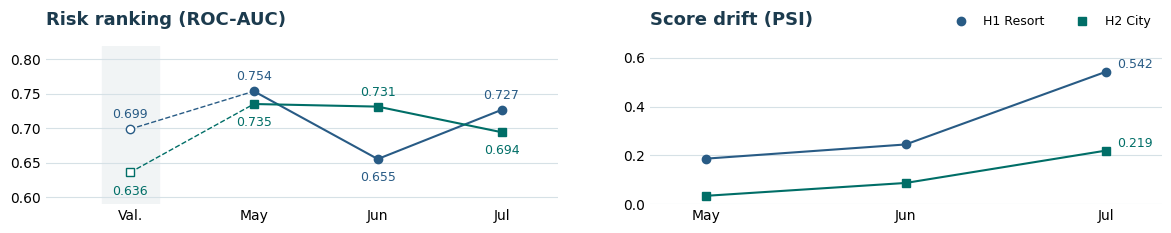

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Figure 9.1 — the same hotel colours and validation reference as the report.
HOTELS = {"H1": ("#285B85", "o", "H1 Resort"), "H2": ("#006E67", "s", "H2 City")}
hotel_legend = [Line2D([], [], color=colour, marker=marker, linestyle="None", label=label)
                for colour, marker, label in HOTELS.values()]
auc = metrics.pivot(index="cutoff_month", columns="Hotel", values="ROC_AUC")
auc.index = pd.to_datetime(auc.index).strftime("%b")
validation = metrics.groupby("Hotel").validation_ROC_AUC.first().to_frame().T
validation.index = ["Val."]
auc = pd.concat([validation, auc])
psi = metrics.pivot(index="cutoff_month", columns="Hotel", values="score_PSI")

fig, (ranking, drift) = plt.subplots(1, 2, figsize=(12, 2.6))
for hotel, (colour, marker, label) in HOTELS.items():
    ranking.plot([0, 1], auc[hotel].iloc[:2], color=colour, linestyle="--", linewidth=1)
    ranking.plot(range(1, len(auc)), auc[hotel].iloc[1:], color=colour, marker=marker)
    ranking.plot(0, auc[hotel].iloc[0], color=colour, marker=marker, markerfacecolor="white")
    for position, value in enumerate(auc[hotel]):
        offset = 8 if value == auc.iloc[position].max() else -16
        ranking.annotate(f"{value:.3f}", (position, value), xytext=(0, offset),
                         textcoords="offset points", ha="center", color=colour, fontsize=9)
    drift.plot(range(len(psi)), psi[hotel], color=colour, marker=marker, label=label)
    drift.annotate(f"{psi[hotel].iloc[-1]:.3f}", (len(psi) - 1, psi[hotel].iloc[-1]),
                   xytext=(8, 3), textcoords="offset points", color=colour, fontsize=9)

ranking.axvspan(-0.23, 0.23, color="#F1F4F5", zorder=0)
ranking.set(xticks=range(len(auc)), xticklabels=auc.index, ylim=(0.59, 0.82),
            yticks=[0.60, 0.65, 0.70, 0.75, 0.80])
drift.set(xticks=range(len(psi)), xticklabels=pd.to_datetime(psi.index).strftime("%b"),
          ylim=(0, max(0.65, psi.max().max() * 1.15)), yticks=[0, 0.2, 0.4, 0.6])
for ax, title in [(ranking, "Risk ranking (ROC-AUC)"), (drift, "Score drift (PSI)")]:
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color="#1C3B4E", pad=15)
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.grid(axis="y", color="#D6E1E6")
    ax.tick_params(length=0)
    ax.margins(x=0.14)
drift.legend(handles=hotel_legend, loc="lower right", bbox_to_anchor=(1, 1.04), ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.05, right=0.98, bottom=0.16, top=0.77, wspace=0.18)
fig.savefig(output_dir / "figure_9_1.png", dpi=160)
plt.show()

Figure 9.1 compares validation with May–July 2017. H1's July score shift did not coincide with a sustained decline in ROC-AUC. H2 stayed above its validation benchmark.

Risk ranking does not tell us whether monthly cancellation totals are accurate. For Figure 9.2, sum the booking probabilities and compare the forecast with observed cancellations and no-shows.
Forecast error is predicted minus observed: positive values mean overestimation. Labels are rounded to whole bookings, as in the report.

In [7]:
metrics[["Hotel", "cutoff_month", "expected_cancellations",
         "actual_cancellations", "bias_bookings", "daily_count_MAE"]]

,Hotel,cutoff_month,expected_cancellations,actual_cancellations,bias_bookings,daily_count_MAE
0,H1,2017-05,54.283,70.000,-15.717,1.329
2,H1,2017-06,45.927,48.000,-2.073,1.034
4,H1,2017-07,48.031,67.000,-18.969,1.268
1,H2,2017-05,248.163,181.000,67.163,3.276
3,H2,2017-06,225.543,140.000,85.543,3.418
5,H2,2017-07,181.081,126.000,55.081,2.407


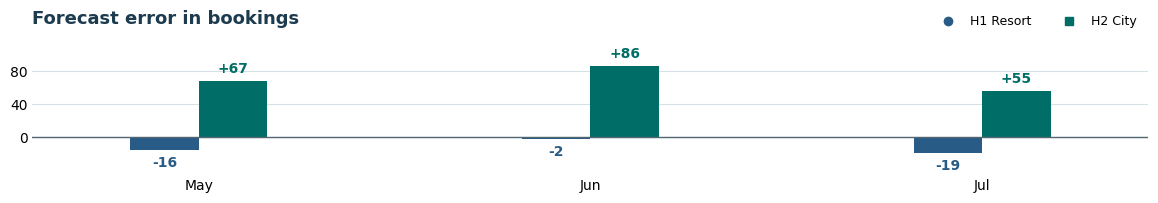

In [8]:
# Figure 9.2 — monthly forecast error, rounded to whole bookings.
forecast_error = metrics.pivot(index="cutoff_month", columns="Hotel", values="bias_bookings")
forecast_error.index = pd.to_datetime(forecast_error.index).strftime("%b")
ax = forecast_error.plot.bar(figsize=(12, 2.2), color=[HOTELS[h][0] for h in forecast_error],
                             width=0.35, rot=0)
ax.axhline(0, color="#516671", linewidth=1)
ax.set_title("Forecast error in bookings", loc="left", fontsize=13, fontweight="bold", color="#1C3B4E", pad=15)
ax.set(xlabel="", ylabel="", yticks=[0, 40, 80])
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.grid(axis="y", color="#D6E1E6")
ax.set_axisbelow(True)
ax.tick_params(length=0)
for hotel, bars in zip(forecast_error.columns, ax.containers):
    ax.bar_label(bars, fmt="%+.0f", padding=4, color=HOTELS[hotel][0], fontweight="bold")
ax.legend(handles=hotel_legend, loc="lower right",
          bbox_to_anchor=(1, 1.04), ncol=2, frameon=False, fontsize=9)
ax.margins(y=0.25)
plt.subplots_adjust(left=0.05, right=0.98, bottom=0.18, top=0.77)
plt.savefig(output_dir / "figure_9_2.png", dpi=160)
plt.show()

### Supporting EDA: booking mix

Changes in lead time, market segment and distribution channel help identify what to investigate when scores shift.
`change_pp` is the change from validation in percentage points. These comparisons show associations, not causes.

In [9]:
mix = pd.read_csv(output_dir / "input_mix.csv")
mix["absolute_change"] = mix.change_pp.abs()
largest_changes = (
    mix.sort_values("absolute_change", ascending=False)
    .groupby(["Hotel", "cutoff_month"]).head(2)
    .sort_values(["Hotel", "cutoff_month"])
)
largest_changes[["Hotel", "cutoff_month", "feature", "category",
                 "validation_share", "current_share", "change_pp"]]

,Hotel,cutoff_month,feature,category,validation_share,current_share,change_pp
9,H1,2017-05,MarketSegment,Offline TA/TO,0.206,0.359,15.218
0,H1,2017-05,LeadTime,181+ days,0.246,0.377,13.078
38,H1,2017-06,MarketSegment,Groups,0.192,0.035,-15.648
31,H1,2017-06,LeadTime,91–180 days,0.227,0.377,15.085
68,H1,2017-07,MarketSegment,Groups,0.192,0.000,-19.186
60,H1,2017-07,LeadTime,181+ days,0.246,0.354,10.769
15,H2,2017-05,LeadTime,31–60 days,0.234,0.154,-7.987
17,H2,2017-05,LeadTime,91–180 days,0.225,0.303,7.794
44,H2,2017-06,LeadTime,181+ days,0.204,0.342,13.860
47,H2,2017-06,LeadTime,91–180 days,0.225,0.355,12.966


## 5. Summary

For the May–July replay with the saved project models, keep both models for now:

- **H1:** monitor PSI and ROC-AUC together to see whether score shifts are followed by weaker risk ranking.
- **H2:** forecasts were too high in all three months. Check calibration across risk groups and monitor whether the bias persists.
- **Follow-up:** persistent bias or declining ranking should prompt a data-quality and calibration review before considering retraining. Evaluate any adjustment on later bookings for probability accuracy, monthly totals and risk ranking.

The table below totals each booking once using the latest monthly assessment.
Reassess these conclusions if the dates or models change.

In [10]:
totals = metrics.groupby("Hotel")[["bookings", "expected_cancellations", "actual_cancellations"]].sum(min_count=1)

# Keep actual totals pending if any month still has unresolved bookings.
for hotel in totals.index:
    complete = metrics.loc[metrics.Hotel.eq(hotel), "outcome_status"].eq("complete").all()
    if not complete:
        totals.loc[hotel, "actual_cancellations"] = float("nan")

display(totals)
print("Output:", output_dir.relative_to(project_root))

,bookings,expected_cancellations,actual_cancellations
Hotel,,,
H1,2704,148.241,185.000
H2,5887,654.787,447.000


Output: artifacts/operations/2017-05-01_2017-07-31/080a17eb48faea983781/trends
